# Comunicación de resultados: área quemada en el norte de Bolivia

Este cuaderno prepara los productos para comunicar los resultados de la aplicación integradora: figuras estáticas, animaciones y mapas interactivos. Parte de los GeoTIFF de dNBR generados con `dnbr_mensual.py` y del archivo `datos_areas_quemadas_pc6.nc` guardado al final de `integrador_dnbr_modelo.ipynb`, por lo que no repite el análisis.

Los productos se ordenan como una historia en tres partes.

1. **Contexto**: dónde está la región y qué se observa.
2. **Resultado**: cómo evoluciona la señal en el tiempo y dónde se concentra.
3. **Conclusión**: cómo se compara la observación con el modelo y con MapBiomas.

Al final se guardan los productos en una carpeta, listos para una presentación o para compartir.

## 1. Configuración

In [1]:
import os

import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import Image

import dnbr_vis as dv
import dnbr_analisis as an
import dnbr_comunicacion as dc

# Región y periodo (los mismos de integrador_dnbr_modelo.ipynb)
NOMBRE = "bolivia_beni"
TITULO = "Beni, Bolivia"
BBOX = (-67.0, -14.0, -66.0, -13.0)      # oeste, sur, este, norte
ANIOS = [2019, 2020, 2021]

# Ubicación de los datos
RUTA_DNBR = "salidas_dnbr"                  # GeoTIFF de dnbr_mensual.py
RUTA_NC = "datos_areas_quemadas_bolivia_beni_pc6.nc"               # salida del cuaderno integrador
CARPETA_PRODUCTOS = "productos_presentacion"           # aquí se guardan figuras y mapas

# Escalas de color, fijas para que todos los productos sean comparables
VLIM_DNBR = 0.5        # dNBR y anomalía: de -0.5 a 0.5
VMAX_BAF = 0.2         # fracción quemada: de 0 a 0.2

## 2. Contexto
El primer mapa ubica la caja de estudio. Se puede alternar entre el mapa base y la imagen satelital con el selector de capas (esquina superior derecha).

In [2]:
mapa_ubic = dc.mapa_ubicacion(BBOX, nombre=TITULO, zoom=6)
mapa_ubic

Se leen los tres años de dNBR en una sola serie y se muestra el panel mensual del primer año.

Frozen({'tiempo': 36, 'lat': 1000, 'lon': 1000})


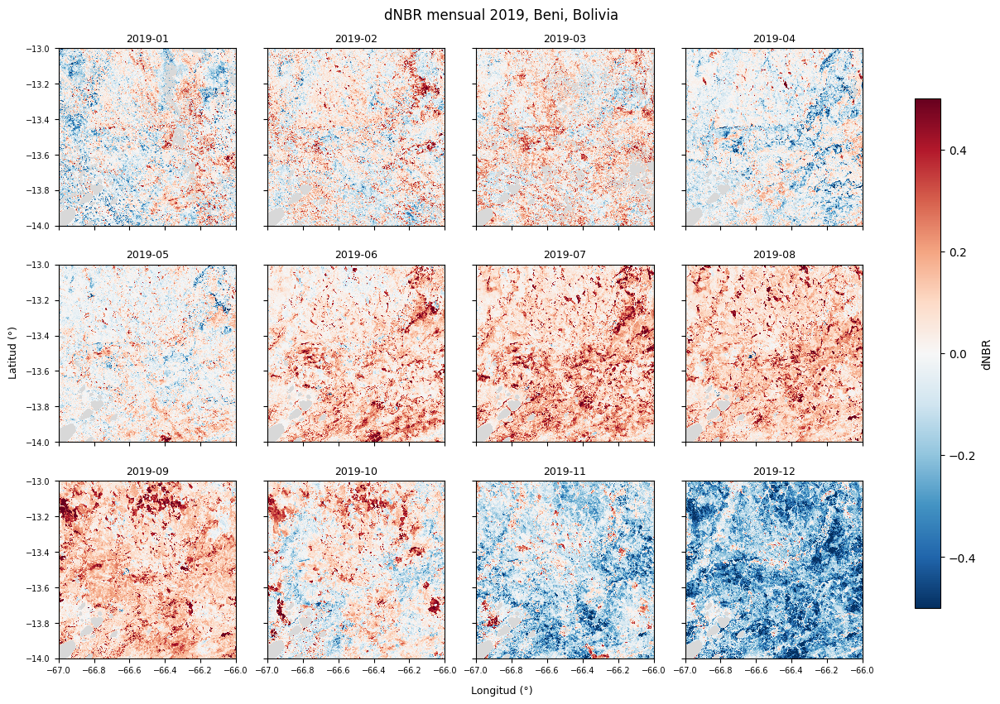

In [3]:
rutas = [f"{RUTA_DNBR}/dnbr_{NOMBRE}_{y}.tif" for y in ANIOS]
dnbr = dv.leer_dnbr(rutas)
print(dnbr.sizes)

fig_panel = dv.panel_mensual(dnbr.sel(tiempo=str(ANIOS[0])), vlim=VLIM_DNBR,
                             titulo=f"dNBR mensual {ANIOS[0]}, {TITULO}")

## 3. Resultado
La animación muestra la secuencia completa de meses. Para el análisis se usa la anomalía espacial, que quita la señal estacional común y resalta los parches que se desvían de su entorno.

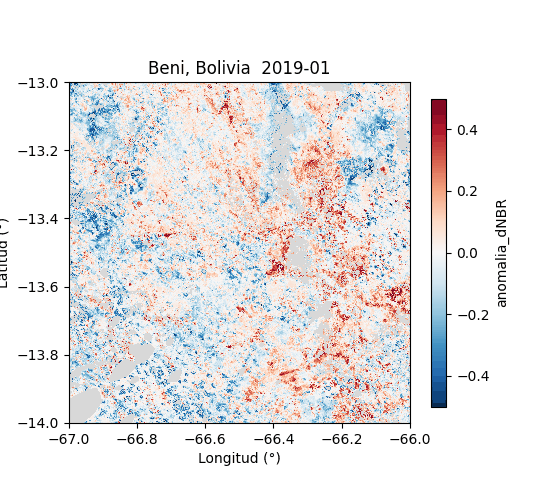

In [4]:
anom = an.anomalia_espacial(dnbr)
os.makedirs(CARPETA_PRODUCTOS, exist_ok=True)

ruta_gif = dv.animar(anom, f"{CARPETA_PRODUCTOS}/anomalia_{NOMBRE}.gif",
                     vlim=VLIM_DNBR, titulo=TITULO)
Image(filename=ruta_gif)

La versión interactiva permite detenerse en un mes y leer el valor de cada punto. Con `paso=10` cada punto es el promedio de 10 x 10 píxeles (alrededor de 1 km), lo que reduce el tamaño del archivo.

In [5]:
fig_anim = dc.mapa_animado(anom, vlim=VLIM_DNBR, paso=10,
                           titulo=f"Anomalía del dNBR, {TITULO}")
fig_anim

Se identifica el mes con mayor fracción quemada observada en la caja y se superpone su anomalía sobre la imagen satelital. Al alternar la opacidad o las capas se puede comparar la ubicación de los parches con el paisaje.

Mes con mayor fracción quemada observada: 2021-08



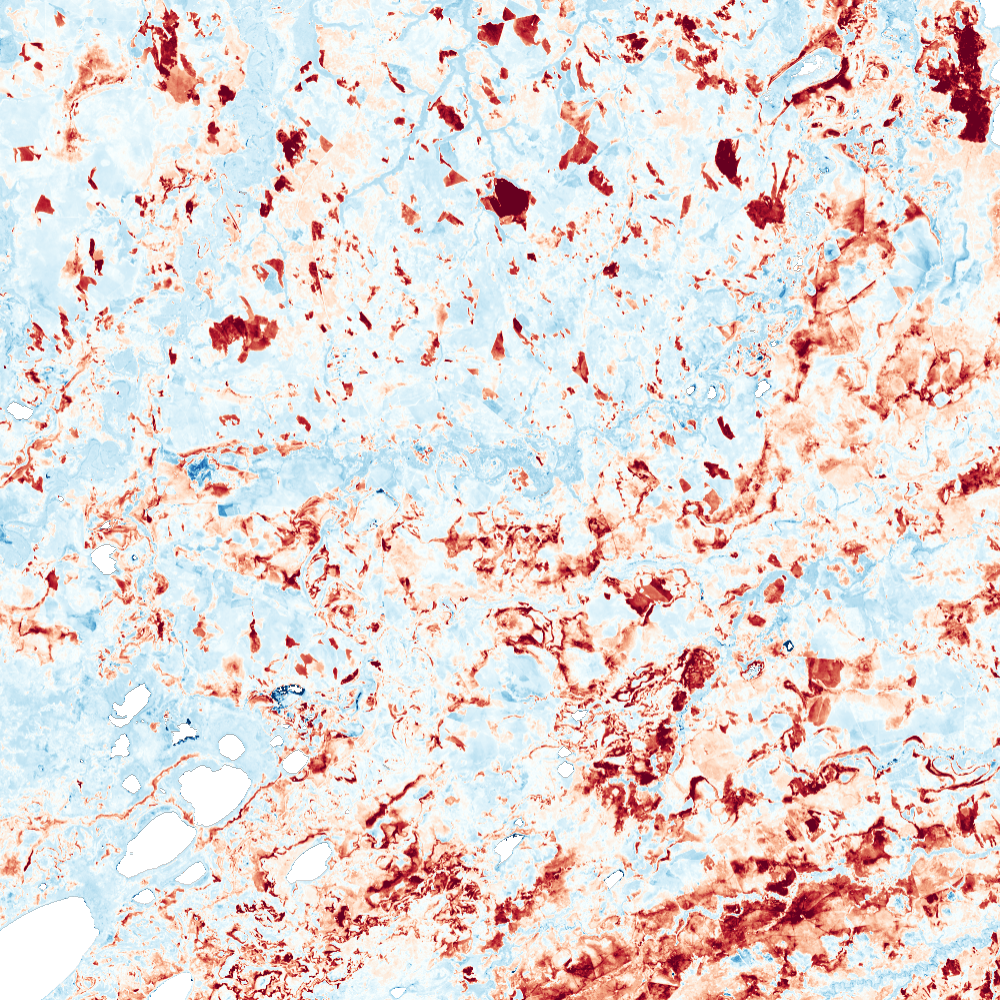

In [6]:
ds = xr.open_dataset(RUTA_NC)
serie = dc.serie_regional(ds)
MES_PICO = serie["BAF_obs"].idxmax().strftime("%Y-%m")
print("Mes con mayor fracción quemada observada:", MES_PICO)

mapa_pico = dc.mapa_raster(anom, MES_PICO, vlim=VLIM_DNBR,
                           titulo=f"Anomalía del dNBR, {MES_PICO}")
mapa_pico

## 4. Conclusión

Las series muestran la fracción quemada media de la caja en cada mes para las tres fuentes. Al hacer clic en la leyenda se oculta o se muestra cada serie.

In [7]:
fig_series = dc.grafico_series(serie, titulo=f"Fracción quemada mensual, {TITULO}")
fig_series

El mapa de celdas muestra la fracción quemada observada en el mes de mayor actividad. Al pasar el cursor sobre una celda aparecen los valores de las tres fuentes.

In [8]:
mapa_obs = dc.mapa_celdas(ds, "BAF_obs", MES_PICO, vmax=VMAX_BAF)
mapa_obs

In [9]:
mapa_modelo = dc.mapa_celdas(ds, "BAF_modelo", MES_PICO, vmax=VMAX_BAF)
mapa_modelo

La comparación es descriptiva. La observación depende del umbral y de la ventana elegidos en el cuaderno integrador, y el modelo estima una fracción mensual por celda, de modo que las diferencias no se interpretan como error del modelo sin antes revisar esas decisiones.

## 5. Productos para la presentación

Se guardan las figuras estáticas en PNG, para insertarlas en diapositivas, y los productos interactivos en HTML, que se abren en cualquier navegador. Los HTML de plotly incluyen la librería completa (unos 5 MB cada uno); con `include_plotlyjs="cdn"` pesan mucho menos, pero requieren conexión a internet para abrirse.

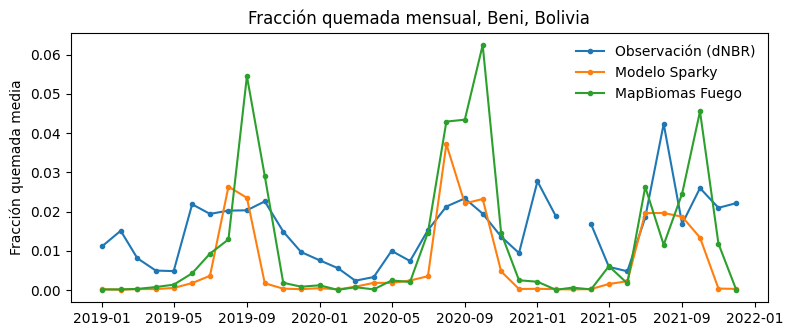

anomalia_animada_bolivia_beni.html
anomalia_bolivia_beni.gif
anomalia_bolivia_beni_2021-08.html
celdas_modelo_bolivia_beni_2021-08.html
celdas_obs_bolivia_beni_2021-08.html
panel_dnbr_2019.png
series_bolivia_beni.html
series_bolivia_beni.png
ubicacion_bolivia_beni.html


In [10]:
# Figuras estáticas
fig_panel.savefig(f"{CARPETA_PRODUCTOS}/panel_dnbr_{ANIOS[0]}.png", dpi=200, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(9, 3.5))
for col in serie.columns:
    ax.plot(serie.index, serie[col], marker="o", ms=3, label=dc.ETIQUETAS.get(col, col))
ax.set_ylabel("Fracción quemada media")
ax.set_title(f"Fracción quemada mensual, {TITULO}")
ax.legend(frameon=False)
fig.savefig(f"{CARPETA_PRODUCTOS}/series_{NOMBRE}.png", dpi=200, bbox_inches="tight")
plt.show()

# Productos interactivos
mapa_ubic.save(f"{CARPETA_PRODUCTOS}/ubicacion_{NOMBRE}.html")
mapa_pico.save(f"{CARPETA_PRODUCTOS}/anomalia_{NOMBRE}_{MES_PICO}.html")
mapa_obs.save(f"{CARPETA_PRODUCTOS}/celdas_obs_{NOMBRE}_{MES_PICO}.html")
mapa_modelo.save(f"{CARPETA_PRODUCTOS}/celdas_modelo_{NOMBRE}_{MES_PICO}.html")
fig_series.write_html(f"{CARPETA_PRODUCTOS}/series_{NOMBRE}.html")
fig_anim.write_html(f"{CARPETA_PRODUCTOS}/anomalia_animada_{NOMBRE}.html")

for archivo in sorted(os.listdir(CARPETA_PRODUCTOS)):
    print(archivo)